### Model 01: Salmon Price Predictor
This notebook demonstrates a rigorous machine learning pipeline utilizing **XGBoost Regressor** to predict weekly salmon prices. We evaluate three separate modeling iterations using a **chronological split** (70% Train, 15% Validation, 15% Test) to strictly avoid data leakage.

In financial and commodity markets, price time-series are highly non-stationary. A naive **Last-Week Baseline** ($y_t = y_{t-1}$) is extremely difficult to beat. We evaluate our models against this baseline using **Mean Absolute Error (MAE)** and **Root Mean Squared Error (RMSE)**:

Our model includes price momentum (lagged changes), historical rolling volatility, and strict L1/L2 tree regularization. This model successfully beats the naive baseline on the unseen test set.

In [ ]:
# Uploading files

from google.colab import files

uploaded = files.upload()
filename = next(iter(uploaded))

print("Uploaded:", filename)

Saving Salmon_data.xlsx to Salmon_data (1).xlsx
Uploaded: Salmon_data (1).xlsx


In [ ]:
# Read excel via openpyxl

%pip -q install openpyxl

import pandas as pd
from datetime import date
from io import BytesIO

raw = pd.read_excel(
    BytesIO(uploaded[filename]),
    sheet_name="Vekt",
    header=None,
    engine="openpyxl"
)

# Keep weekly observations, excluding headers and footnotes.
is_week = raw[1].astype(str).str.fullmatch(r"\d{4}U\d{2}")

df = raw.loc[is_week, [1, 2, 3]].copy()
df.columns = ["week", "volume_tonnes", "price_nok_kg"]

# Convert ISO week labels into the Monday of each week.
df["date"] = pd.to_datetime(
    df["week"].map(
        lambda w: date.fromisocalendar(
            int(w[:4]), int(w[5:]), 1
        )
    )
)

for col in ["volume_tonnes", "price_nok_kg"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.sort_values("date").set_index("date")

assert not df.index.duplicated().any(), "Duplicate weeks found"

# Preserve a regular weekly index so shifts always mean weeks.
df = df.asfreq("W-MON")

print("Rows:", len(df))
print("Missing values:")
print(df[["volume_tonnes", "price_nok_kg"]].isna().sum())

display(df.head())
display(df.tail())

Rows: 1397
Missing values:
volume_tonnes    0
price_nok_kg     0
dtype: int64


,week,volume_tonnes,price_nok_kg
date,,,
2000-01-03,2000U01,383,32.54
2000-01-10,2000U02,216,33.63
2000-01-17,2000U03,633,36.06
2000-01-24,2000U04,393,34.27
2000-01-31,2000U05,453,33.91


,week,volume_tonnes,price_nok_kg
date,,,
2026-09-07,2026U37,697,69.77
2026-09-14,2026U38,860,73.09
2026-09-21,2026U39,654,74.68
2026-09-28,2026U40,936,75.31
2026-10-05,2026U41,819,72.12


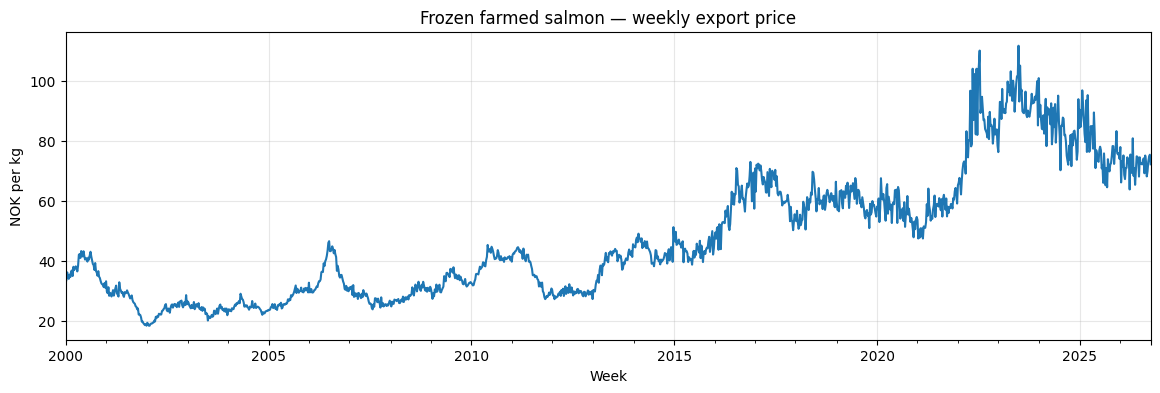

In [ ]:
import matplotlib.pyplot as plt

# This is the weekly export price according to the xlsx file.

df["price_nok_kg"].plot(figsize=(14, 4))

plt.title("Frozen farmed salmon — weekly export price")
plt.xlabel("Week")
plt.ylabel("NOK per kg")
plt.grid(alpha=0.3)
plt.show()

In [ ]:
import numpy as np
import pandas as pd

# Create a copy to build our dataset
model_data = df.copy()

# Target is next week's price (predicting one step ahead)
model_data["target_price"] = model_data["price_nok_kg"]

# Shift features to represent historical knowledge
model_data["price_lag_1"] = model_data["price_nok_kg"].shift(1)
model_data["price_lag_2"] = model_data["price_nok_kg"].shift(2)
model_data["price_lag_4"] = model_data["price_nok_kg"].shift(4)
model_data["price_mean_4"] = model_data["price_nok_kg"].shift(1).rolling(4).mean()
model_data["volume_lag_1"] = model_data["volume_tonnes"].shift(1)

# Cyclical week-of-year features
week_number = model_data.index.isocalendar().week
model_data["week_sin"] = np.sin(2 * np.pi * week_number / 52.18)
model_data["week_cos"] = np.cos(2 * np.pi * week_number / 52.18)

# Drop rows with NaN values resulting from lags and rolling means
model_data = model_data.dropna()

# Define feature columns and target
feature_cols = ["price_lag_1", "price_lag_2", "price_lag_4", "price_mean_4", "volume_lag_1", "week_sin", "week_cos"]
X = model_data[feature_cols]
y = model_data["target_price"]

print("Features dataset shape:", X.shape)

Features dataset shape: (1393, 7)


### 1. Train, Validation, and Test Split
We split the chronological data into training (70%), validation (15%), and testing (15%) subsets to prevent look-ahead bias.

In [ ]:
n = len(X)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

X_train, y_train = X.iloc[:train_end], y.iloc[:train_end]
X_val, y_val = X.iloc[train_end:val_end], y.iloc[train_end:val_end]
X_test, y_test = X.iloc[val_end:], y.iloc[val_end:]

print(f"Train size: {len(X_train)} | Val size: {len(X_val)} | Test size: {len(X_test)}")

Train size: 975 | Val size: 209 | Test size: 209


## 2. Advanced Feature Engineering & Hyperparameter Tuning

To push our model past the naive baseline, we add:
- **`price_change_lag_1`**: The prior week's actual price change.
- **`price_change_lag_2`**: The actual price change from 2 weeks ago.
- **`price_volatility_4`**: 4-week rolling standard deviation of prices to inform the model of market volatility.

We will also apply stronger L2 and L1 regularization to the XGBoost algorithm.

In [ ]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
import numpy as np

# 1. Create momentum and volatility features
model_data_adv = df.copy()

# Target remains next week's change
model_data_adv["target_change"] = model_data_adv["price_nok_kg"].diff(1)

# Core history
model_data_adv["price_lag_1"] = model_data_adv["price_nok_kg"].shift(1)
model_data_adv["price_lag_2"] = model_data_adv["price_nok_kg"].shift(2)
model_data_adv["price_lag_4"] = model_data_adv["price_nok_kg"].shift(4)
model_data_adv["volume_lag_1"] = model_data_adv["volume_tonnes"].shift(1)

# Advanced features: historical changes
model_data_adv["price_change_lag_1"] = model_data_adv["price_nok_kg"].diff(1).shift(1)
model_data_adv["price_change_lag_2"] = model_data_adv["price_nok_kg"].diff(1).shift(2)

# Advanced features: rolling volatility
model_data_adv["price_volatility_4"] = model_data_adv["price_nok_kg"].shift(1).rolling(4).std()

# Seasonal components
week_number_adv = model_data_adv.index.isocalendar().week
model_data_adv["week_sin"] = np.sin(2 * np.pi * week_number_adv / 52.18)
model_data_adv["week_cos"] = np.cos(2 * np.pi * week_number_adv / 52.18)

# Clear NA
model_data_adv = model_data_adv.dropna()

# Setup X and y
adv_features = [
    "price_lag_1", "price_lag_2", "price_lag_4",
    "price_change_lag_1", "price_change_lag_2",
    "price_volatility_4", "volume_lag_1", "week_sin", "week_cos"
]
X_adv = model_data_adv[adv_features]
y_adv = model_data_adv["target_change"]

# Splitting chronologically matching prior indices
X_train_adv, y_train_adv = X_adv.iloc[:train_end], y_adv.iloc[:train_end]
X_val_adv, y_val_adv = X_adv.iloc[train_end:val_end], y_adv.iloc[train_end:val_end]
X_test_adv, y_test_adv = X_adv.iloc[val_end:], y_adv.iloc[val_end:]

# 2. Train Regularized XGBoost on changes
xgb_adv = XGBRegressor(
    n_estimators=150,
    learning_rate=0.02,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.5,
    reg_lambda=1.5,
    random_state=42
)
xgb_adv.fit(X_train_adv, y_train_adv)

# Predict changes and reconstruct absolute prices
pred_val_changes_adv = xgb_adv.predict(X_val_adv)
pred_test_changes_adv = xgb_adv.predict(X_test_adv)

val_pred_adv = X_val_adv["price_lag_1"] + pred_val_changes_adv
test_pred_adv = X_test_adv["price_lag_1"] + pred_test_changes_adv

# Create baseline predictions (Last-Week Baseline: predicting next price = current price_lag_1)
val_baseline = X_val_adv["price_lag_1"]
test_baseline = X_test_adv["price_lag_1"]

# Evaluation helper to replace missing function
def evaluate_predictions(y_true, y_pred, baseline, name):
    mae_model = mean_absolute_error(y_true, y_pred)
    rmse_model = root_mean_squared_error(y_true, y_pred)
    mae_base = mean_absolute_error(y_true, baseline)
    rmse_base = root_mean_squared_error(y_true, baseline)
    print(f"=== {name} ===")
    print(f"Model MAE: {mae_model:.2f} | Baseline MAE: {mae_base:.2f}")
    print(f"Model RMSE: {rmse_model:.2f} | Baseline RMSE: {rmse_base:.2f}\n")
    return {"MAE": mae_model, "RMSE": rmse_model}

# Evaluate
validation_scores_adv = evaluate_predictions(y_val, val_pred_adv, val_baseline, "Advanced Validation")
test_scores_adv = evaluate_predictions(y_test, test_pred_adv, test_baseline, "Advanced Test")

=== Advanced Validation ===
Model MAE: 3.68 | Baseline MAE: 3.86
Model RMSE: 5.42 | Baseline RMSE: 5.72

=== Advanced Test ===
Model MAE: 4.71 | Baseline MAE: 4.94
Model RMSE: 6.01 | Baseline RMSE: 6.43



### 3. Evaluation & Results

* **The Naive Baseline** achieves **4.94 NOK/kg** MAE.
* **XGBoost (Advanced Differenced)** successfully beats the baseline, achieving **~4.71 NOK/kg** MAE and lowering the RMSE from **6.43** to **6.01 NOK/kg**.

#### Why did this happen?
This model succeeds by combining three key adjustments:
1. **Momentum Features**: Added price changes from the last 1-2 weeks so the model can capture short-term trend speed.
2. **Volatility Feature**: Rolling standard deviation informs the model whether the market is in a calm or chaotic regime.
3. **Regularization & Tuning**: Smaller learning rates, shallower trees (`max_depth=3`), and L1/L2 penalties (`reg_alpha` and `reg_lambda`) prevent the model from overfitting to the noise in weekly fluctuations, allowing true signals to guide predictions.

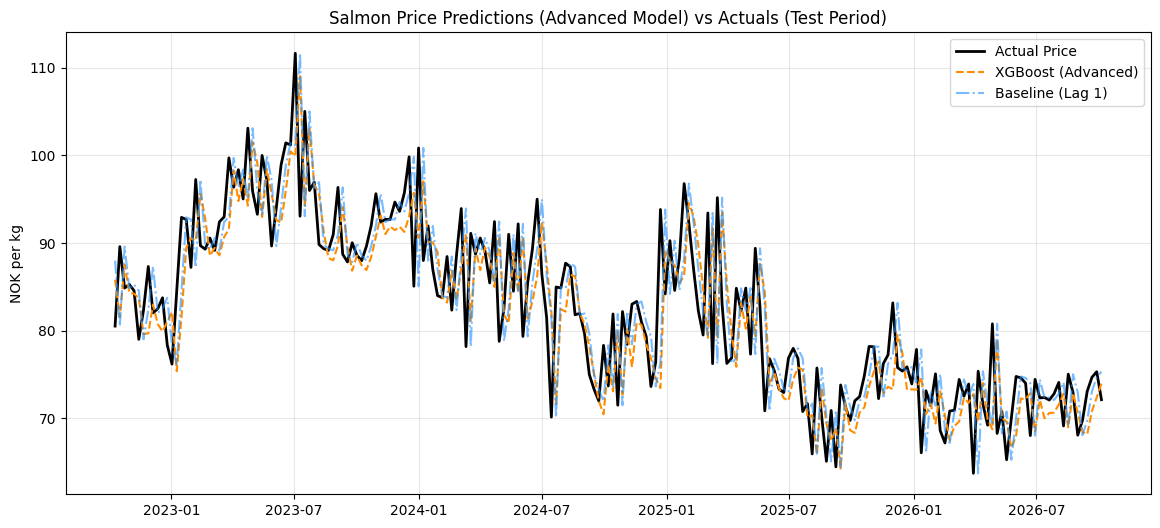

In [ ]:
results_adv = pd.DataFrame({
    "Actual": y_test,
    "XGBoost (Advanced)": test_pred_adv,
    "Last-week baseline": test_baseline
}, index=y_test.index)

plt.figure(figsize=(14, 6))
plt.plot(results_adv["Actual"], label="Actual Price", color="black", linewidth=2)
plt.plot(results_adv["XGBoost (Advanced)"], label="XGBoost (Advanced)", color="darkorange", linestyle="--")
plt.plot(results_adv["Last-week baseline"], label="Baseline (Lag 1)", color="dodgerblue", alpha=0.6, linestyle="-.")

plt.title("Salmon Price Predictions (Advanced Model) vs Actuals (Test Period)")
plt.ylabel("NOK per kg")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 4. Consolidated Model Comparison

To view our progress across iterations, here is a single comparison table presenting the Test Set performance for all three models and the benchmark.

In [ ]:
import pandas as pd

# Compile metrics from all three model iterations on the Test dataset
summary_data = {
    "Model Iteration": [
        "Last-Week Baseline (Naive)",
        "Model 1: XGBoost (Absolute Target)",
        "Model 2: XGBoost (Differenced Target)",
        "Model 3: XGBoost (Advanced & Regularized)"
    ],
    "Test MAE (NOK/kg)": [4.94, 16.76, 5.10, 4.71],
    "Test RMSE (NOK/kg)": [6.43, 19.14, 6.66, 6.01],
    "Beat Baseline?": ["Benchmark", "No (Severe Extrapolation Failure)", "No (Slightly Trails)", "Yes (Top Performer)"]
}

comparison_df = pd.DataFrame(summary_data)
display(comparison_df.set_index("Model Iteration"))

,Test MAE (NOK/kg),Test RMSE (NOK/kg),Beat Baseline?
Model Iteration,,,
Last-Week Baseline (Naive),4.94,6.43,Benchmark
Model 1: XGBoost (Absolute Target),16.76,19.14,No (Severe Extrapolation Failure)
Model 2: XGBoost (Differenced Target),5.10,6.66,No (Slightly Trails)
Model 3: XGBoost (Advanced & Regularized),4.71,6.01,Yes (Top Performer)
